In [28]:
# Helper methods

# Print all frames
def print_frames(frames):
    for i, frame in enumerate(frames):
        plt.imshow(frame, cmap='gray')
        plt.title(f'Frame {i}')
        plt.axis('off')
        plt.show()

In [29]:
# FAST corner detection from HW 8

# Radius of 3, clockwise, from the slides
circle = [(0, -3), (1, -3), (2, -2), (3, -1), (3, 0), (3, 1), (2, 2), (1, 3), (0, 3), (-1, 3), (-2, 2), (-3, 1), (-3, 0), (-3, -1), (-2, -2), (-1, -3)]

# Name each pixel based on if it's above, below, or within the threshold
def fastLabels(values, center, T):
    labels = []
    for v in values:
        if v > center + T:
            labels.append("Above")
        elif v < center - T:
            labels.append("Below")
        else:
            labels.append("Within")
    return labels

# Going twice to catch wrap arounds
def longestContinuous(labels):
    longest = 0
    count = 0
    prev = "Within"
    for label in (labels + labels):
        if label == "Within":
            count = 0
        elif label == prev:
            count += 1
        else:
            count = 1
        prev = label
        longest = max(longest, count)
    return min(longest, 16)

def FAST(img, T, n=9):
    points = []
    for y in range(3, img.shape[0]-3):
        for x in range(3, img.shape[1]-3):
            # Make the array of surrounding circle pixels
            values = [img[y+dy, x+dx] for dx, dy in circle]
            if longestContinuous(fastLabels(values, img[y, x], T)) >= n:
                points.append((x, y))
    return points

Part 1: Video normalization and resizing

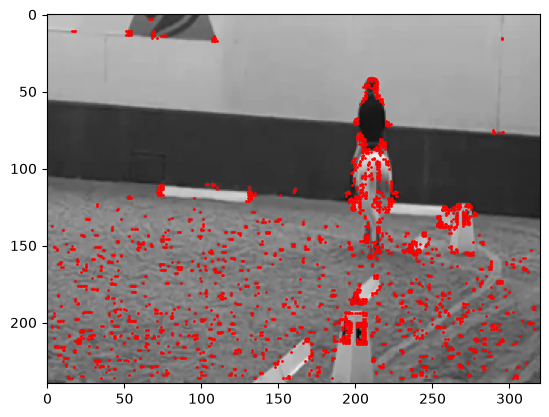

In [ ]:
import imageio.v3 as iio
from skimage.color import rgb2gray
from skimage.transform import resize
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import convolve
import pandas as pd
from skimage.registration import optical_flow_ilk

# Constants
FRAME_RANGE = (0, 10)
TARGET_FPS = 5
RESIZE = (240, 320) # height then width, 240p
VID_FPS = iio.immeta("Input/horse.mp4")["fps"]
FEATURE_THRESHOLD = 0.05

fps_ratio = VID_FPS / TARGET_FPS

# Load the frame range as grayscale and resize them
video_frames = np.array([resize(rgb2gray(iio.imread("Input/horse.mp4", index=round(i*fps_ratio))), RESIZE) for i in range(*FRAME_RANGE)])

Part 2: FAST feature extraction

In [ ]:
FAST_points = []
for frame in video_frames:
    FAST_points.append(FAST(frame, T=FEATURE_THRESHOLD))

#print(FAST_points)

# plot points on the first frame
plt.imshow(video_frames[0], cmap='gray')
for (x, y) in FAST_points[0]:
    plt.scatter(x, y, color='red', s=1)

plt.show()

#print_frames(video_frames)

Part 3: Between-frame feature matching